In [3]:
import os, sys
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')   # 防止 Windows 上 OpenMP 运行库重复加载导致内核崩溃
from pathlib import Path
ROOT = Path.cwd()                      # 本 notebook 所在目录 = 项目根目录
sys.path.insert(0, str(ROOT))

SMOKE = False      
WORKERS = 3        
THREADS = 4        

print('1/4 导入 torch …', flush=True)
import torch
print('    torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), flush=True)
print('2/4 导入 numpy / pandas / scipy …', flush=True)
import numpy as np, pandas as pd, scipy
print('3/4 导入 matplotlib …', flush=True)
import matplotlib
print('4/4 导入实验代码 cpm …', flush=True)
from cpm import config as C
from cpm.experiments import (run_experiment, run_group, run_tuning_search, run_tuning_confirm, run_upper_bound, run_exploit,
                             run_overhead, results_root, figures_root, load_tuned)
from cpm.network import run_netshock, run_recovery
from cpm import analysis as A, figures as Fg
from cpm.calibration import calibration_report
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
print('✅ 设置完成 | 模式:', '冒烟' if SMOKE else '正式')
print('结果目录:', results_root(SMOKE), '| 图目录:', figures_root(SMOKE))

1/4 导入 torch …
    torch 2.12.1+cu132 | CUDA: True
2/4 导入 numpy / pandas / scipy …
3/4 导入 matplotlib …
4/4 导入实验代码 cpm …
✅ 设置完成 | 模式: 正式
结果目录: C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\results | 图目录: C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\figures


电价自检：复现 2024-12 官方工商业分时价格，最大误差 0.0e+00 元/kWh
  residential  峰 0.5250  平 0.4150  谷 0.2950  峰谷比 1.78
  commercial   峰 0.7422  平 0.5233  谷 0.3560  峰谷比 2.09
成本前提：min c^run/P^EB = 1.48（应 > 1），max c^run/P^ES = 0.37
  α = 0.05: P^EB 高于 c^run 的(卡型, 电价类别)组合 0 / 14
  α = 0.2: P^EB 高于 c^run 的(卡型, 电价类别)组合 7 / 14
  α = 0.4: P^EB 高于 c^run 的(卡型, 电价类别)组合 14 / 14
⏳ 生成数据集 N3000_T2800_43261e831d：3000 散户，训练+验证 3000 天，测试 100 天
✅ 数据集完成：显存 >8 GB 占 9.8%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.7%
显存：>8 GB 9.8%，>24 GB 0.0%，产消者任务超出自有卡显存 5.7%
保留价：φ 中位数 0.197（锚点 0.20），φ > 0.404 的比例 16.8%（锚点 16.2%），θ ∈ [0.25, 0.35]，λ ∈ [0.15, 0.45]
  反事实保留价 / ECC 零售价（中位数，按卡型）：3070 0.37，3080 0.42，3090 0.40，4060 0.35，4070 0.32，4080 0.37，4090 0.38
  🖼 00_data/Fig_tariff_demand.png（绘图数据：00_data/data/Fig_tariff_demand*.csv）


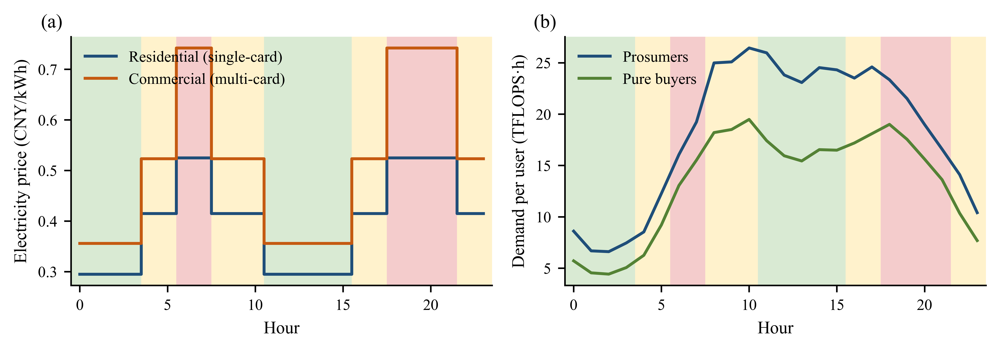

  🖼 00_data/FigS_vram.png（绘图数据：00_data/data/FigS_vram*.csv）


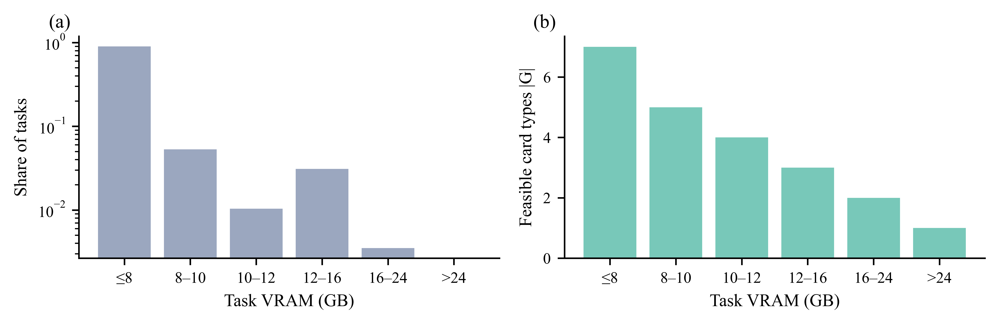

In [2]:
calibration_report(SMOKE)
Fg.fig_tariff_demand(smoke=SMOKE); Fg.fig_vram(smoke=SMOKE)

In [3]:
display(run_tuning_search(workers=WORKERS, smoke=SMOKE, threads=THREADS))

📋 25 个作业：['tune_t00', 'tune_t01', 'tune_t02', 'tune_t03', 'tune_t04', 'tune_t05', 'tune_t06', 'tune_t07', 'tune_t08', 'tune_t09', 'tune_t10', 'tune_t11', 'tune_t12', 'tune_t13', 'tune_t14', 'tune_t15', 'tune_t16', 'tune_t17', 'tune_t18', 'tune_t19', 'tune_t20', 'tune_t21', 'tune_t22', 'tune_t23', 'tune_t24']
[1/25] tune_t00 / seed 0 → ok（28.6 min）| 已用 28.7 min
[2/25] tune_t01 / seed 0 → ok（31.9 min）| 已用 32.0 min
[7/25] tune_t06 / seed 0 → ok（30.2 min）| 已用 91.2 min
[8/25] tune_t07 / seed 0 → ok（30.5 min）| 已用 93.2 min
[9/25] tune_t08 / seed 0 → ok（33.0 min）| 已用 96.9 min
[13/25] tune_t12 / seed 0 → ok（47.2 min）| 已用 167.6 min
[14/25] tune_t14 / seed 0 → ok（45.1 min）| 已用 172.5 min
[15/25] tune_t13 / seed 0 → ok（47.6 min）| 已用 174.5 min
[16/25] tune_t17 / seed 0 → ok（27.9 min）| 已用 202.4 min
[17/25] tune_t15 / seed 0 → ok（35.9 min）| 已用 203.4 min
[18/25] tune_t16 / seed 0 → ok（34.6 min）| 已用 207.1 min
[19/25] tune_t19 / seed 0 → ok（27.5 min）| 已用 231.0 min
[20/25] tune_t18 / seed 0 → ok（30.6 min）

,trial,seed,experiment,gamma,lr,entropy_coef,clip,ppo_epochs,val_unit_welfare,test_unit_welfare,train_minutes,rank
16,16,0,tune_t16,0.139,0.000471,0.00194,0.125,9,159.614944,159.050010,33.975401,1
1,1,0,tune_t01,0.034,0.000508,0.03940,0.247,6,158.867822,158.700402,31.205404,2
23,23,0,tune_t23,0.220,0.000142,0.04480,0.299,7,158.036671,157.639235,35.537782,3
14,14,0,tune_t14,0.042,0.000034,0.00924,0.252,7,157.735648,157.499879,44.322343,4
10,10,0,tune_t10,0.392,0.000043,0.00357,0.136,8,157.551311,157.278218,33.408784,5
8,8,0,tune_t08,0.167,0.000057,0.01490,0.192,8,157.370598,157.024498,32.421343,6
15,15,0,tune_t15,0.265,0.000068,0.02700,0.267,9,157.168945,156.848069,35.225979,7
6,6,0,tune_t06,0.315,0.000627,0.02360,0.113,5,156.941696,156.915140,29.488057,8
22,22,0,tune_t22,0.492,0.000246,0.01000,0.186,5,155.845339,155.429924,34.418476,9
9,9,0,tune_t09,0.095,0.000038,0.00678,0.261,4,155.734570,155.440954,28.508839,10


In [4]:
display(run_tuning_confirm(workers=WORKERS, smoke=SMOKE, threads=THREADS))

📋 6 个作业：['tune_confirm_t16', 'tune_confirm_t01', 'tune_confirm_t23']
[1/6] tune_confirm_t01 / seed 1 → ok（33.7 min）| 已用 33.8 min
[2/6] tune_confirm_t16 / seed 2 → ok（36.8 min）| 已用 36.9 min
[3/6] tune_confirm_t16 / seed 1 → ok（36.8 min）| 已用 36.9 min
[4/6] tune_confirm_t01 / seed 2 → ok（35.3 min）| 已用 69.1 min
[5/6] tune_confirm_t23 / seed 2 → ok（40.3 min）| 已用 77.2 min
[6/6] tune_confirm_t23 / seed 1 → ok（40.5 min）| 已用 77.4 min
✅ 完成
✅ 选定试验 16：{'gamma': 0.139, 'lr': 0.000471, 'entropy_coef': 0.00194, 'clip': 0.125, 'ppo_epochs': 9}（3 个种子验证均值 158.75）


,trial,val_mean,val_sd,test_mean,n_seeds
1,16,158.748020,0.760923,158.325674,3
0,1,157.674184,1.033957,157.244096,3
2,23,157.541689,0.728414,157.202926,3


选定的参数： {'gamma': 0.139, 'lr': 0.000471, 'entropy_coef': 0.00194, 'clip': 0.125, 'ppo_epochs': 9}


,trial,seed,experiment,gamma,lr,entropy_coef,clip,ppo_epochs,val_unit_welfare,test_unit_welfare,train_minutes,rank,val_mean,val_sd,test_mean,n_seeds,selected
0,16,0,tune_t16,0.139,0.000471,0.00194,0.125,9,159.614944,159.050010,33.975401,1,158.748020,0.760923,158.325674,3.0,True
1,1,0,tune_t01,0.034,0.000508,0.03940,0.247,6,158.867822,158.700402,31.205404,2,157.674184,1.033957,157.244096,3.0,False
2,23,0,tune_t23,0.220,0.000142,0.04480,0.299,7,158.036671,157.639235,35.537782,3,157.541689,0.728414,157.202926,3.0,False
3,14,0,tune_t14,0.042,0.000034,0.00924,0.252,7,157.735648,157.499879,44.322343,4,NaN,NaN,NaN,NaN,False
4,10,0,tune_t10,0.392,0.000043,0.00357,0.136,8,157.551311,157.278218,33.408784,5,NaN,NaN,NaN,NaN,False
5,8,0,tune_t08,0.167,0.000057,0.01490,0.192,8,157.370598,157.024498,32.421343,6,NaN,NaN,NaN,NaN,False
6,15,0,tune_t15,0.265,0.000068,0.02700,0.267,9,157.168945,156.848069,35.225979,7,NaN,NaN,NaN,NaN,False
7,6,0,tune_t06,0.315,0.000627,0.02360,0.113,5,156.941696,156.915140,29.488057,8,NaN,NaN,NaN,NaN,False
8,22,0,tune_t22,0.492,0.000246,0.01000,0.186,5,155.845339,155.429924,34.418476,9,NaN,NaN,NaN,NaN,False
9,9,0,tune_t09,0.095,0.000038,0.00678,0.261,4,155.734570,155.440954,28.508839,10,NaN,NaN,NaN,NaN,False


  🖼 tuning/FigS_tuning.png（绘图数据：tuning/data/FigS_tuning*.csv）


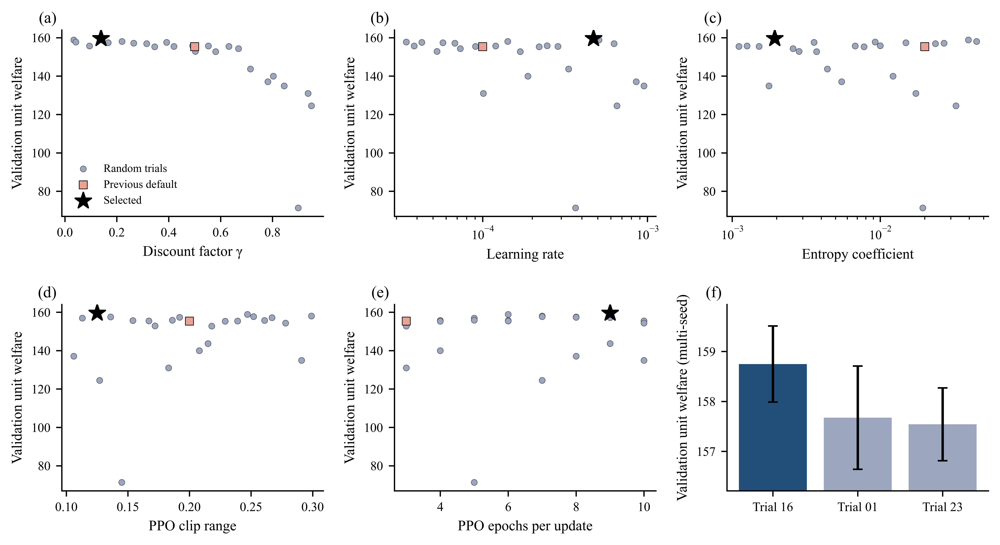

In [5]:
print('选定的参数：', load_tuned(SMOKE))
display(A.table_tuning(SMOKE)); Fg.fig_tuning(smoke=SMOKE)

In [6]:
run_experiment('main', workers=1, smoke=SMOKE, threads=THREADS)

📋 实验 main：Main experiment (single seed) | 种子 [0] | 方法 ['marl', 'cda', 'sdr', 'mmr', 'mcafee'] | N=3000, 训练 2800 天
▶ main / seed 0
   ↺ 参数与种子完全相同，复用 tune_t16\seed_0 的结果
   [CDA   ] 单位福利  135.95 | 日福利   16394.1 | 中介均利   2104.9 | 内部流量占比 0.655
   [SDR   ] 单位福利   67.99 | 日福利    8198.9 | 中介均利   1881.8 | 内部流量占比 0.307
   [MMR   ] 单位福利  122.11 | 日福利   14725.7 | 中介均利    930.0 | 内部流量占比 0.593
   [MCAFEE] 单位福利   74.19 | 日福利    8946.8 | 中介均利    862.3 | 内部流量占比 0.391
   → ok（2.2 min）
✅ main 完成


[('main', 0, 'ok', 2.1731635689735413)]

,experiment,seed,done,N,intermediaries,train_days_cfg,test_days,episodes_logged,train_minutes,device,data,reused_from,evaluated
0,main,0,True,3000,3,2800,100,2800,34.0,cuda,N3000_T2800_43261e831d,tune_t16\seed_0,"cda,marl,mcafee,mmr,sdr"


,method,n_seeds,Welfare (CNY/day),Unit welfare,Avg. intermediary profit,Buyer savings,Prosumer savings,Retail volume,ECC fallback volume,Internal flow share,ECC retail revenue,ECC buy-back spend,Operator surplus,"ΔUnit welfare (MARL − method), daily","Wilcoxon p (daily, supplementary)"
0,MARL,1,19179.99,159.05,1927.13,2.80,5.18,827775.50,266228.74,0.76,7319.91,166.87,0.00,NaN,NaN
1,CDA,1,16394.12,135.95,2104.90,0.94,4.40,728219.64,384292.70,0.65,10899.66,273.51,0.00,22.832095,3.896560e-18
2,SDR,1 (deterministic rule),8198.91,67.99,1881.81,0.76,0.89,336291.36,759204.85,0.31,22502.40,9.79,0.00,92.622020,3.896560e-18
3,MMR,1 (deterministic rule),14725.72,122.11,929.96,2.88,4.45,662275.57,453725.93,0.59,13281.60,146.05,0.00,36.303983,3.896560e-18
4,McAfee,1,8946.75,74.19,862.33,0.01,2.07,433059.66,674482.67,0.39,20008.33,755.39,2004.25,85.612157,3.896560e-18


,method,Internal flow share,Intermediary throughput,Leakage to ECC,HHI (retail),Aggregation in-degree,Bidirectional node share,Cross-layer substitution share,Share of retail trades at bid cap,Edge value: sellers,Edge value: intermediaries,Edge value: buyers,Retail fill rate,Fallback self-supply / day,Eligible-but-unfilled bids / day,Sell-all → ECC events / day,P1 price / ECC retail price,Mean reservation / ECC retail price,Share of idle capacity sold,P1 edges / day,P2 edges / day,"P1 edge persistence (Jaccard, day to day)","P2 edge persistence (Jaccard, day to day)",Active seller share / day,Seller degree (intermediaries / day),Buyer degree (intermediaries / day),Intermediary in-degree / day,Intermediary out-degree / day,Gini of seller volume,Gini of buyer volume,Top-10% seller volume share,CV of daily P1 volume,CV of daily P2 volume
0,MARL,0.76,0.94,0.06,0.35,56.79,0.25,0.33,0.00,7554.65,6273.52,7530.15,0.87,319.45,1718.55,1340.22,0.47,0.36,0.53,4537.12,5561.67,0.83,0.70,0.94,2.31,2.33,1512.37,1853.89,0.52,0.57,0.39,0.07,0.10
1,CDA,0.65,0.90,0.10,0.42,37.58,0.23,0.12,0.00,8154.79,7452.10,2727.18,0.76,37.36,4411.22,1586.91,0.55,0.41,0.49,4356.26,5124.36,0.77,0.64,0.85,2.43,2.05,1452.09,1708.12,0.59,0.57,0.43,0.04,0.08
2,SDR,0.31,0.99,0.01,0.77,24.43,0.17,0.16,0.01,888.12,5664.63,1985.68,0.38,0.21,10914.36,1585.94,0.29,0.34,0.21,1210.50,2135.38,0.74,0.44,0.41,1.40,1.30,403.50,711.79,0.80,0.71,0.63,0.16,0.15
3,MMR,0.59,0.94,0.06,0.41,31.70,0.21,0.07,0.00,5554.13,3170.73,6980.66,0.68,287.99,6065.98,795.86,0.48,0.34,0.43,3267.36,4665.22,0.75,0.58,0.76,2.06,1.91,1089.12,1555.07,0.68,0.59,0.50,0.04,0.06
4,McAfee,0.39,0.65,0.35,0.36,34.37,0.20,0.06,0.99,4538.07,5626.67,174.12,0.48,234.03,3265.43,2292.24,0.48,0.41,0.41,2986.95,3060.92,0.61,0.39,0.65,2.17,1.64,995.65,1020.31,0.70,0.68,0.51,0.05,0.10


,inter,theta,rho,p1_in,p2_out,salvage,profit,throughput,leakage,retail_share,purchase_share,p1_avg_price,p2_avg_price,in_degree
0,inter_0,1.3,0.032351,341495.539496,332840.043797,8655.4957,2331.293170,0.974654,0.025346,0.402090,0.389563,0.015522,0.023911,70.948720
1,inter_1,1.0,0.035000,323370.882697,304046.830098,19324.0526,2144.404858,0.940242,0.059758,0.367306,0.368888,0.016010,0.025069,58.248824
2,inter_2,0.7,0.038953,211744.311299,190888.630200,20855.6811,1305.699672,0.901505,0.098495,0.230604,0.241549,0.015696,0.025192,41.176964


,seed,curve,metric,plateau_from,n_points,plateau_mean,half_rel_change,slope_per100_rel,slope_p,cv,converged,peak_episode,peak_value,plateau_vs_peak
0,0,train,unit_welfare,1959,841,162.023007,-0.002985,-0.001383,1.486927e-01,0.067367,True,NaN,NaN,NaN
1,0,train,inter_profit_avg,1959,841,1827.048688,0.001750,-0.000670,8.364756e-01,0.228087,True,NaN,NaN,NaN
2,0,train,buyer_savings_pc,1959,841,2.660372,0.042919,0.009345,8.880325e-17,0.080606,False,NaN,NaN,NaN
3,0,train,prosumer_savings_pc,1959,841,5.275982,-0.032747,-0.008627,2.431290e-10,0.096934,False,NaN,NaN,NaN
4,0,validation,val_unit_welfare,1959,17,161.105397,-0.000583,-0.000838,3.499024e-01,0.008488,True,1700.0,165.091743,-0.024146
5,0,validation,val_welfare,1959,17,18117.926668,-0.000583,-0.000838,3.499024e-01,0.008488,True,1700.0,18566.231449,-0.024146
6,0,validation,val_inter_profit_avg,1959,17,1761.296173,-0.000018,0.000346,8.532132e-01,0.017461,True,1350.0,1999.439039,-0.119105
7,0,validation,val_buyer_savings_pc,1959,17,2.674030,0.044403,0.009501,2.785067e-08,0.024809,False,2799.0,2.778997,-0.037772
8,0,validation,val_prosumer_savings_pc,1959,17,4.965434,-0.010954,-0.003824,2.390245e-02,0.017205,True,600.0,5.544428,-0.104428
9,0,validation,val_p1_price_rel,1959,17,0.478219,-0.028479,-0.006218,7.282396e-08,0.016389,False,400.0,0.551586,-0.133010


  🖼 main/Fig_training.png（绘图数据：main/data/Fig_training*.csv）





  🖼 main/Fig_surplus_dynamics.png（绘图数据：main/data/Fig_surplus_dynamics*.csv）


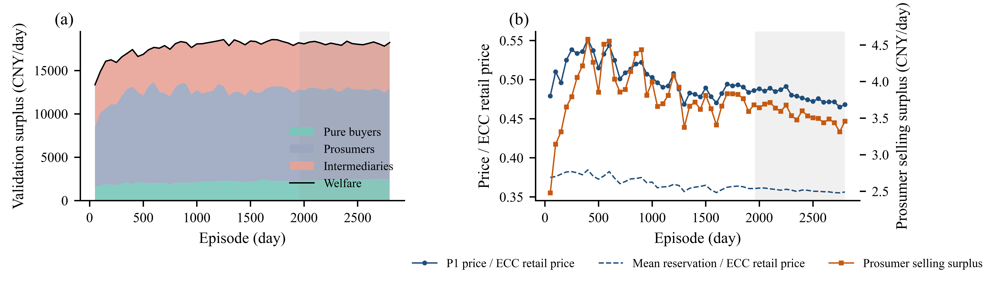

  🖼 main/Fig_methods.png（绘图数据：main/data/Fig_methods*.csv）


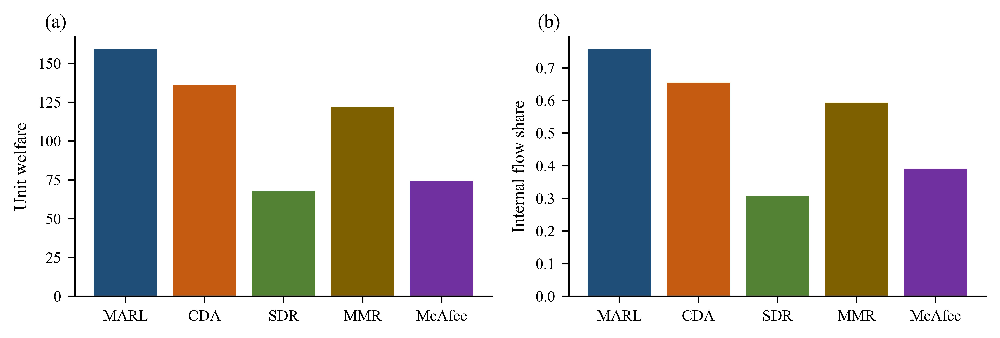

  🖼 main/Fig_flow_network.png（绘图数据：main/data/Fig_flow_network*.csv）


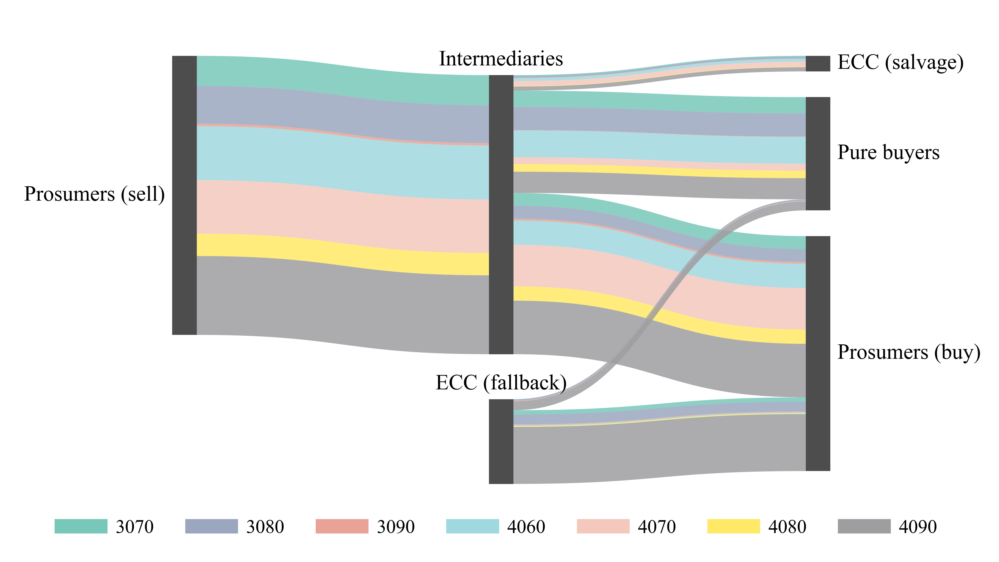

  🖼 main/Fig_hourly_spread.png（绘图数据：main/data/Fig_hourly_spread*.csv）


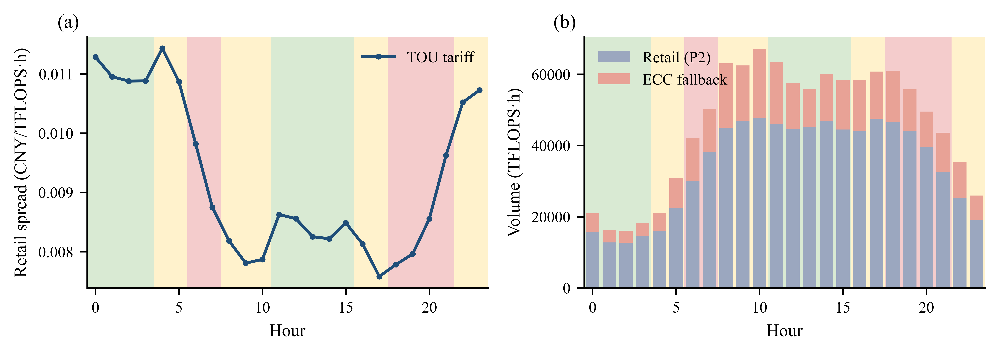

  🖼 main/Fig_price_ratio.png（绘图数据：main/data/Fig_price_ratio*.csv）


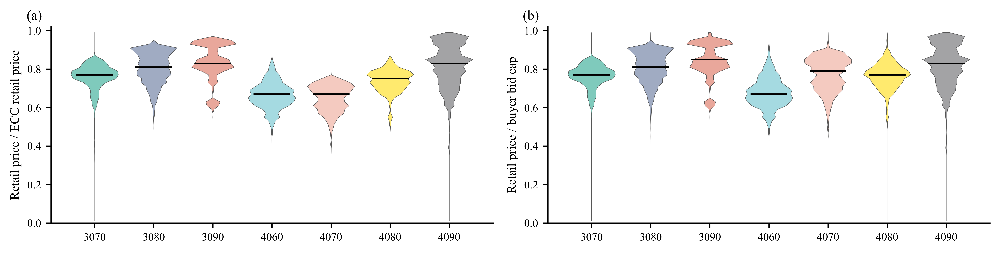

  🖼 main/Fig_substitution.png（绘图数据：main/data/Fig_substitution*.csv）


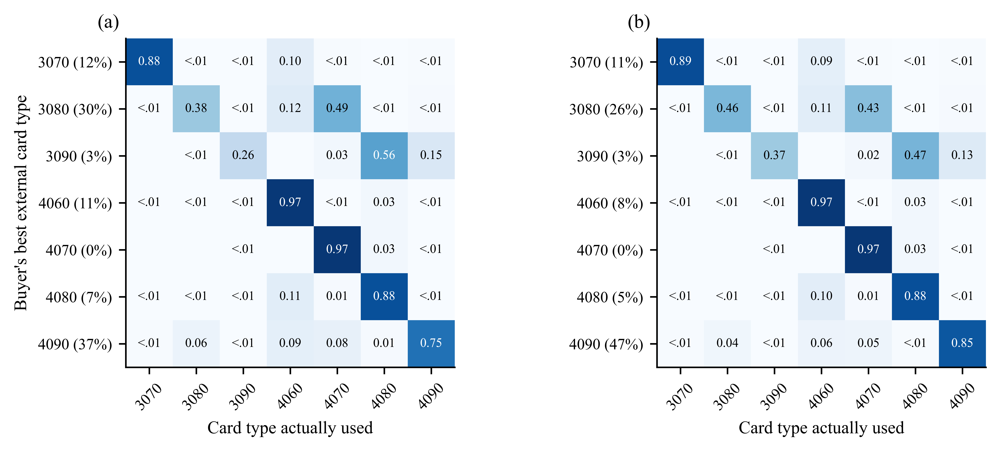

  🖼 main/Fig_bidirectional.png（绘图数据：main/data/Fig_bidirectional*.csv）


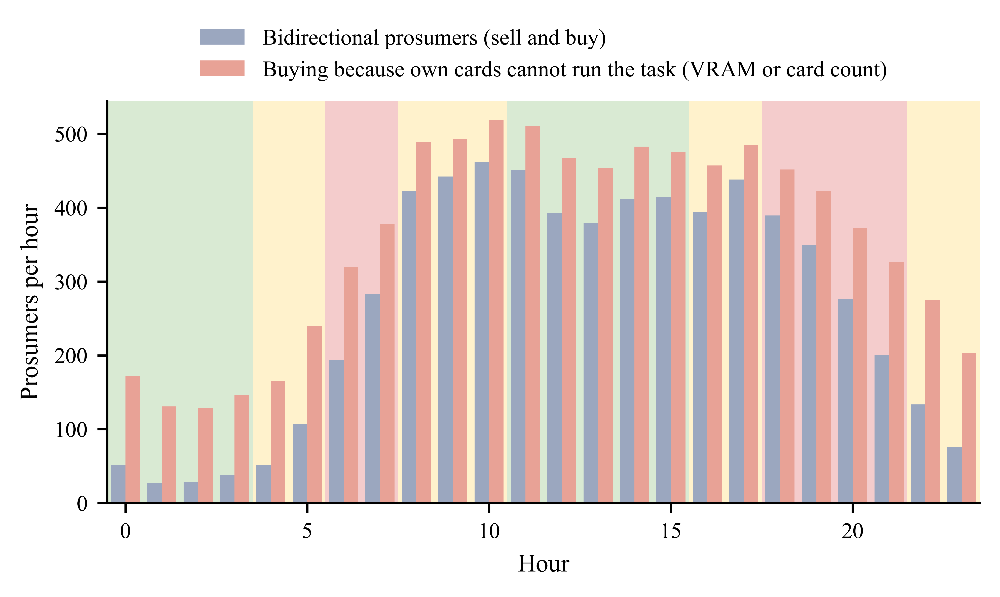

  🖼 main/Fig_surplus.png（绘图数据：main/data/Fig_surplus*.csv）


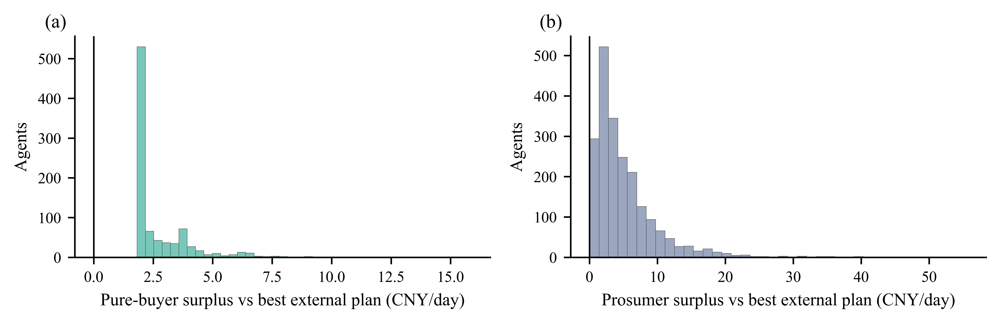

  🖼 main/Fig_network_structure.png（绘图数据：main/data/Fig_network_structure*.csv）


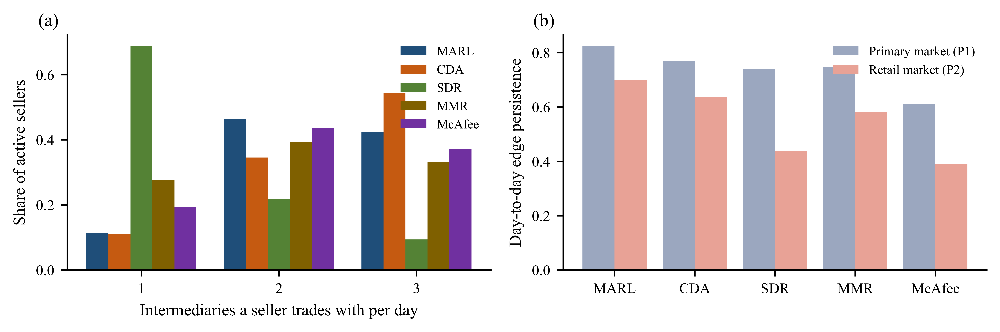

  🖼 main/Fig_network_formation.png（绘图数据：main/data/Fig_network_formation*.csv）





In [7]:
display(A.describe_runs(SMOKE, ['main']))            # 应为 N=3000、train_days_cfg=2800、episodes_logged=2800
t3 = A.table_methods('main', SMOKE); display(t3[[c for c in t3.columns if not c.endswith('_mean')]])
display(A.table_network('main', SMOKE))
display(A.table_intermediaries('main', 'marl', SMOKE))
display(A.convergence_table('main', SMOKE))
Fg.experiment_figures('main', SMOKE)                  # figures/main/

✅ 上界完成：单位福利上界 223.34（5.2 min）


,method,unit_welfare,efficiency
0,Upper bound (LP),223.342238,1.000000
1,MARL,159.050010,0.712136
2,CDA,135.948230,0.608699
3,SDR,67.989462,0.304418
4,MMR,122.113008,0.546753
5,McAfee,74.190949,0.332185


  🖼 efficiency/Fig_efficiency.png（绘图数据：efficiency/data/Fig_efficiency*.csv）


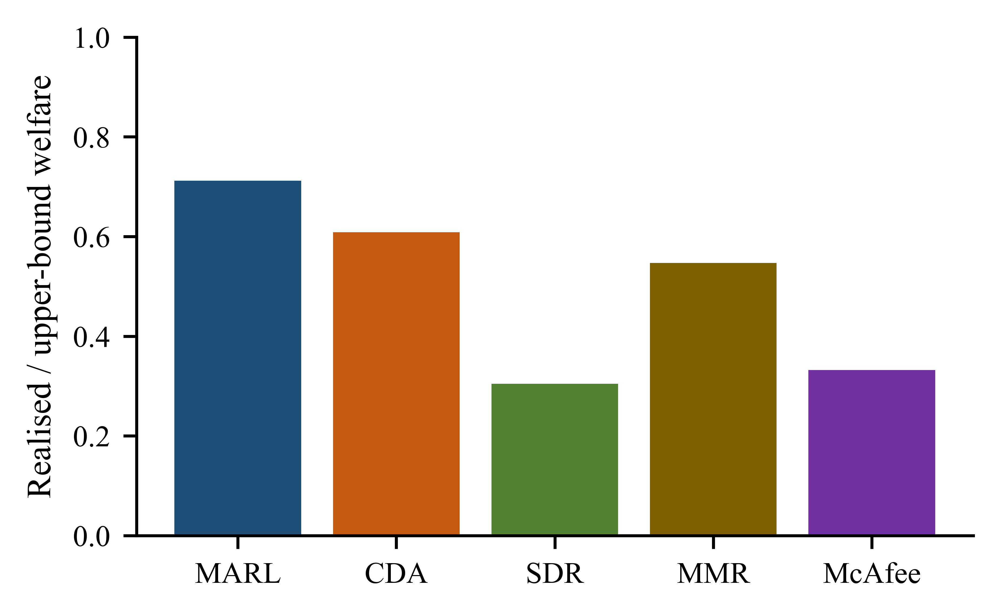

In [8]:
run_upper_bound('main', SMOKE)
display(A.table_efficiency('main', SMOKE)); Fg.fig_efficiency(smoke=SMOKE)

📋 实验 robust：Multi-seed robustness (seed is the only change) | 种子 [0, 1, 2, 3, 4] | 方法 ['marl', 'cda', 'sdr', 'mmr', 'mcafee'] | N=3000, 训练 2800 天
[1/5] robust / seed 0 → ok（0.0 min）| 已用 0.1 min
[2/5] robust / seed 1 → ok（1.1 min）| 已用 1.2 min
[3/5] robust / seed 2 → ok（1.1 min）| 已用 1.2 min
[4/5] robust / seed 3 → ok（54.6 min）| 已用 54.7 min
[5/5] robust / seed 4 → ok（54.7 min）| 已用 55.9 min
✅ robust 完成


,method,n_seeds,Welfare (CNY/day),Unit welfare,Avg. intermediary profit,Buyer savings,Prosumer savings,Retail volume,ECC fallback volume,Internal flow share,ECC retail revenue,ECC buy-back spend,Operator surplus,"ΔUnit welfare (MARL − method), daily","Wilcoxon p (daily, supplementary)","ΔUnit welfare (MARL − method), seed-paired",Seeds where MARL is better
0,MARL,5,19033.71 ± 164.58,157.84 ± 1.36,2166.08 ± 177.33,2.25 ± 0.36,5.00 ± 0.25,827898.90 ± 12524.57,267553.03 ± 6474.40,0.76 ± 0.01,7314.56 ± 150.77,158.92 ± 23.46,0.00 ± 0.00,NaN,NaN,NaN,NaN
1,CDA,5,16389.49 ± 9.27,135.91 ± 0.08,2104.44 ± 0.50,0.94 ± 0.00,4.40 ± 0.00,728039.47 ± 340.46,384500.79 ± 414.21,0.65 ± 0.00,10906.02 ± 12.57,273.19 ± 0.28,0.00 ± 0.00,21.607883,3.896560e-18,21.93 ± 1.37,5/5
2,SDR,1 (deterministic rule),8198.91,67.99,1881.81,0.76,0.89,336291.36,759204.85,0.31,22502.40,9.79,0.00,91.356496,3.896560e-18,89.85 ± 1.36,5/5
3,MMR,1 (deterministic rule),14725.72,122.11,929.96,2.88,4.45,662275.57,453725.93,0.59,13281.60,146.05,0.00,35.038459,3.896560e-18,35.72 ± 1.36,5/5
4,McAfee,5,8902.80 ± 36.02,73.83 ± 0.30,861.57 ± 16.56,0.01 ± 0.00,2.07 ± 0.01,431064.95 ± 1662.08,676398.65 ± 1628.80,0.39 ± 0.00,20064.68 ± 45.29,754.79 ± 4.48,1974.93 ± 26.03,84.733932,3.896560e-18,84.01 ± 1.41,5/5


,seed,curve,metric,plateau_from,n_points,plateau_mean,half_rel_change,slope_per100_rel,slope_p,cv,converged,peak_episode,peak_value,plateau_vs_peak
0,0,train,unit_welfare,1959,841,162.023007,-0.002985,-0.001383,1.486927e-01,0.067367,True,NaN,NaN,NaN
1,0,train,inter_profit_avg,1959,841,1827.048688,0.001750,-0.000670,8.364756e-01,0.228087,True,NaN,NaN,NaN
2,0,train,buyer_savings_pc,1959,841,2.660372,0.042919,0.009345,8.880325e-17,0.080606,False,NaN,NaN,NaN
3,0,train,prosumer_savings_pc,1959,841,5.275982,-0.032747,-0.008627,2.431290e-10,0.096934,False,NaN,NaN,NaN
4,0,validation,val_unit_welfare,1959,17,161.105397,-0.000583,-0.000838,3.499024e-01,0.008488,True,1700.0,165.091743,-0.024146
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,4,validation,val_net_edges_p2,1959,17,5451.994118,-0.004146,-0.000642,3.159073e-01,0.006079,True,1000.0,5551.000000,-0.017836
86,4,validation,val_net_active_sellers,1959,17,0.951064,-0.002611,-0.000597,2.095990e-01,0.004558,True,1200.0,0.976333,-0.025881
87,4,validation,val_net_seller_degree,1959,17,2.371249,-0.013700,-0.003269,1.331868e-03,0.011235,True,1000.0,2.526064,-0.061287
88,4,validation,val_net_buyer_degree,1959,17,2.199119,-0.002810,-0.000191,7.301915e-01,0.005167,True,650.0,2.253404,-0.024090


  🖼 robust/FigS_robust_network_formation.png（绘图数据：robust/data/FigS_robust_network_formation*.csv）





  🖼 robust/FigS_robust_training.png（绘图数据：robust/data/FigS_robust_training*.csv）





  🖼 robust/FigS_robust_methods.png（绘图数据：robust/data/FigS_robust_methods*.csv）


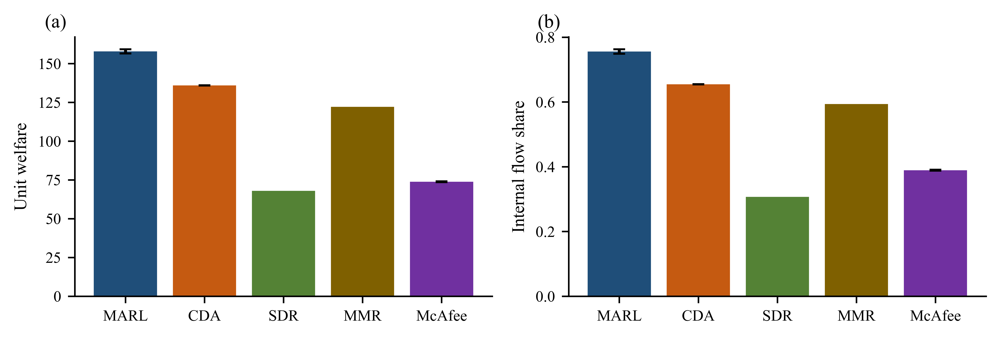

In [9]:
run_experiment('robust', workers=WORKERS, smoke=SMOKE, threads=THREADS)
t = A.table_methods('robust', SMOKE); display(t[[c for c in t.columns if not c.endswith('_mean')]])
display(A.convergence_table('robust', SMOKE)); Fg.robust_figures(SMOKE)

📋 24 个作业：['abl_gamma099', 'abl_relu_qty', 'abl_reward_abs', 'abl_mappo', 'abl_shared_inter', 'x_rulep_learnq', 'x_learnp_ruleq', 'x_rulep_ruleq']
[1/24] abl_gamma099 / seed 2 → ok（48.0 min）| 已用 48.1 min
[2/24] abl_gamma099 / seed 1 → ok（48.2 min）| 已用 48.2 min
[3/24] abl_gamma099 / seed 0 → ok（48.8 min）| 已用 48.9 min
[4/24] abl_relu_qty / seed 0 → ok（49.2 min）| 已用 97.3 min
[5/24] abl_relu_qty / seed 1 → ok（49.3 min）| 已用 97.5 min
[6/24] abl_relu_qty / seed 2 → ok（49.2 min）| 已用 98.1 min
[10/24] abl_mappo / seed 0 → ok（42.8 min）| 已用 189.2 min
[11/24] abl_mappo / seed 1 → ok（42.7 min）| 已用 189.4 min
[12/24] abl_mappo / seed 2 → ok（42.6 min）| 已用 189.7 min
[13/24] abl_shared_inter / seed 0 → ok（29.5 min）| 已用 218.7 min
[14/24] abl_shared_inter / seed 1 → ok（29.5 min）| 已用 218.9 min
[15/24] abl_shared_inter / seed 2 → ok（29.3 min）| 已用 219.0 min
[16/24] x_rulep_learnq / seed 1 → ok（36.9 min）| 已用 255.8 min
[17/24] x_rulep_learnq / seed 0 → ok（37.2 min）| 已用 255.8 min
[18/24] x_rulep_learnq / seed 2 →

,variant,experiment,n_seeds,unit_welfare,unit_welfare_mean,inter_profit_avg,inter_profit_avg_mean,buyer_savings_pc,buyer_savings_pc_mean,prosumer_savings_pc,prosumer_savings_pc_mean,internal_flow_share,internal_flow_share_mean,Δ vs full,Δ_mean,seeds worse,paired t p
0,Full method (IPPO),robust,3,158.33 ± 0.63,158.325674,2148.85 ± 198.95,2148.853279,2.42 ± 0.38,2.420191,4.98 ± 0.23,4.984717,0.76 ± 0.00,0.756633,NaN,NaN,NaN,NaN
1,γ = 0.99,abl_gamma099,3,115.34 ± 4.67,115.343039,1126.05 ± 102.58,1126.049460,1.60 ± 0.57,1.595944,4.33 ± 0.11,4.330869,0.56 ± 0.02,0.562340,-42.98 ± 4.38,-42.982635,3/3,0.003438
2,"Quantity max(0, a)",abl_relu_qty,3,156.68 ± 0.62,156.684450,2194.54 ± 369.24,2194.540626,2.23 ± 0.21,2.231418,4.91 ± 0.60,4.906106,0.75 ± 0.01,0.754453,-1.64 ± 0.01,-1.641224,3/3,0.000007
3,Absolute reward,abl_reward_abs,3,155.91 ± 1.76,155.908046,2210.09 ± 224.11,2210.085015,2.32 ± 0.56,2.324922,4.80 ± 0.17,4.799243,0.76 ± 0.01,0.755392,-2.42 ± 1.31,-2.417628,3/3,0.085706
4,MAPPO (central critic),abl_mappo,3,159.03 ± 0.91,159.026230,2141.09 ± 96.17,2141.086911,2.45 ± 0.08,2.449196,5.02 ± 0.13,5.023610,0.77 ± 0.00,0.765442,0.70 ± 1.44,0.700556,1/3,0.488274
5,Shared intermediary net,abl_shared_inter,3,157.33 ± 0.35,157.328082,923.35 ± 399.74,923.354449,2.58 ± 0.15,2.575365,6.61 ± 0.63,6.611641,0.76 ± 0.01,0.757881,-1.00 ± 0.92,-0.997592,3/3,0.202184


,experiment,price,quantity,n_seeds,unit_welfare,unit_welfare_mean,inter_profit_avg
0,robust,learned,learned,3,158.33 ± 0.63,158.325674,2148.853279
1,x_rulep_learnq,rule,learned,3,138.26 ± 1.86,138.257522,2434.318380
2,x_learnp_ruleq,learned,rule,3,145.74 ± 2.55,145.738795,2470.441531
3,x_rulep_ruleq,rule,rule,3,130.11 ± 4.12,130.113431,2757.364690
0,main effects,price effect 17.85 ± 3.12,quantity effect 10.37 ± 1.34,3,interaction 4.44 ± 4.69,NaN,NaN


  🖼 ablation/Fig_ablation.png（绘图数据：ablation/data/Fig_ablation*.csv）


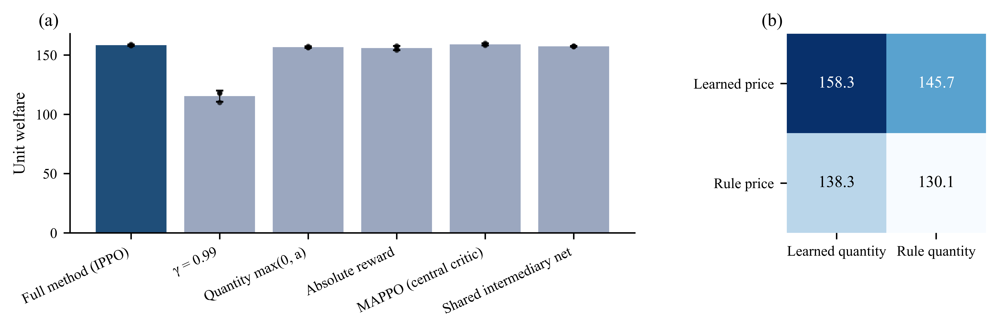

In [10]:
run_group(['abl_gamma099', 'abl_relu_qty', 'abl_reward_abs', 'abl_mappo', 'abl_shared_inter',
           'x_rulep_learnq', 'x_learnp_ruleq', 'x_rulep_ruleq'], workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_ablation(SMOKE)); display(A.table_attribution(SMOKE)); Fg.fig_ablation(smoke=SMOKE)

,method,Internal flow share,Intermediary throughput,Leakage to ECC,HHI (retail),Aggregation in-degree,Bidirectional node share,Cross-layer substitution share,Share of retail trades at bid cap,Edge value: sellers,Edge value: intermediaries,Edge value: buyers,Retail fill rate,Fallback self-supply / day,Eligible-but-unfilled bids / day,Sell-all → ECC events / day,P1 price / ECC retail price,Mean reservation / ECC retail price,Share of idle capacity sold,P1 edges / day,P2 edges / day,"P1 edge persistence (Jaccard, day to day)","P2 edge persistence (Jaccard, day to day)",Active seller share / day,Seller degree (intermediaries / day),Buyer degree (intermediaries / day),Intermediary in-degree / day,Intermediary out-degree / day,Gini of seller volume,Gini of buyer volume,Top-10% seller volume share,CV of daily P1 volume,CV of daily P2 volume
0,MARL,0.76,0.94,0.06,0.35,56.79,0.25,0.33,0.00,7554.65,6273.52,7530.15,0.87,319.45,1718.55,1340.22,0.47,0.36,0.53,4537.12,5561.67,0.83,0.70,0.94,2.31,2.33,1512.37,1853.89,0.52,0.57,0.39,0.07,0.10
1,CDA,0.65,0.90,0.10,0.42,37.58,0.23,0.12,0.00,8154.79,7452.10,2727.18,0.76,37.36,4411.22,1586.91,0.55,0.41,0.49,4356.26,5124.36,0.77,0.64,0.85,2.43,2.05,1452.09,1708.12,0.59,0.57,0.43,0.04,0.08
2,SDR,0.31,0.99,0.01,0.77,24.43,0.17,0.16,0.01,888.12,5664.63,1985.68,0.38,0.21,10914.36,1585.94,0.29,0.34,0.21,1210.50,2135.38,0.74,0.44,0.41,1.40,1.30,403.50,711.79,0.80,0.71,0.63,0.16,0.15
3,MMR,0.59,0.94,0.06,0.41,31.70,0.21,0.07,0.00,5554.13,3170.73,6980.66,0.68,287.99,6065.98,795.86,0.48,0.34,0.43,3267.36,4665.22,0.75,0.58,0.76,2.06,1.91,1089.12,1555.07,0.68,0.59,0.50,0.04,0.06
4,McAfee,0.39,0.65,0.35,0.36,34.37,0.20,0.06,0.99,4538.07,5626.67,174.12,0.48,234.03,3265.43,2292.24,0.48,0.41,0.41,2986.95,3060.92,0.61,0.39,0.65,2.17,1.64,995.65,1020.31,0.70,0.68,0.51,0.05,0.10


  🖼 main/Fig_network_structure.png（绘图数据：main/data/Fig_network_structure*.csv）


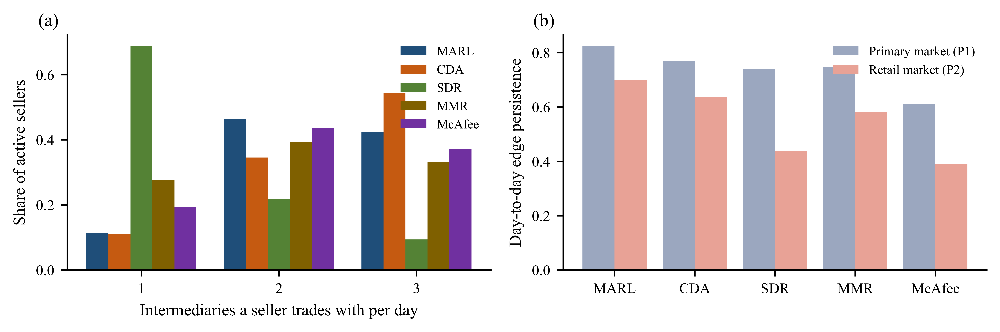

In [11]:
display(A.table_network('main', SMOKE)); Fg.fig_network_structure('main', SMOKE)

📋 4 个作业：['struct_n_consumers_300', 'struct_n_consumers_1000', 'struct_n_consumers_2000', 'struct_n_consumers_5000']
[1/4] struct_n_consumers_1000 / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/4] struct_n_consumers_2000 / seed 0 → skip（0.0 min）| 已用 0.0 min
[3/4] struct_n_consumers_300 / seed 0 → skip（0.0 min）| 已用 0.0 min
[4/4] struct_n_consumers_5000 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,n_consumers,300,struct_n_consumers_300,MARL,164.605286,191.790683,2.408200,4.861654,0.775143,0.335167,8.947268e+04,8.069422e+04,0.818181,0.690812
1,n_consumers,300,struct_n_consumers_300,CDA,143.614480,172.703877,0.937413,4.663685,0.677895,0.416148,8.395260e+04,6.991193e+04,0.790904,0.651739
2,n_consumers,300,struct_n_consumers_300,SDR,48.034665,120.679640,0.563297,0.554028,0.212747,0.761504,2.201948e+04,2.148204e+04,0.704152,0.413013
3,n_consumers,300,struct_n_consumers_300,MMR,128.449873,86.494170,2.715383,4.337876,0.604486,0.420118,6.931300e+04,6.317437e+04,0.741451,0.617512
4,n_consumers,300,struct_n_consumers_300,McAfee,53.903996,-0.801717,0.007229,1.788327,0.293043,0.344723,5.858950e+04,2.986798e+04,0.752042,0.428830
5,n_consumers,1000,struct_n_consumers_1000,MARL,161.968257,741.270887,2.275103,5.192140,0.772781,0.347210,3.165803e+05,2.919649e+05,0.823363,0.666036
6,n_consumers,1000,struct_n_consumers_1000,CDA,141.054318,703.212021,0.927393,4.726300,0.681112,0.408310,2.901807e+05,2.562731e+05,0.780945,0.637765
7,n_consumers,1000,struct_n_consumers_1000,SDR,61.701132,569.925740,0.710140,0.812696,0.282833,0.788431,1.056499e+05,1.045961e+05,0.717065,0.430914
8,n_consumers,1000,struct_n_consumers_1000,MMR,127.727977,327.515920,2.888396,4.727191,0.620018,0.408838,2.530623e+05,2.351275e+05,0.746626,0.590588
9,n_consumers,1000,struct_n_consumers_1000,McAfee,67.292383,193.593534,0.006116,2.115438,0.360090,0.333642,2.207893e+05,1.343601e+05,0.672360,0.382798


  🖼 struct_n_consumers/Fig_struct_n_consumers.png（绘图数据：struct_n_consumers/data/Fig_struct_n_consumers*.csv）





In [3]:
run_group([n for n, e in C.EXPERIMENTS.items() if e['group'] == 'struct_n_consumers'], workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('n_consumers', SMOKE)); Fg.fig_axis('n_consumers', SMOKE)

📋 5 个作业：['struct_n_intermediaries_1', 'struct_n_intermediaries_2', 'struct_n_intermediaries_4', 'struct_n_intermediaries_5', 'struct_n_intermediaries_8']
[1/5] struct_n_intermediaries_1 / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/5] struct_n_intermediaries_5 / seed 0 → skip（0.0 min）| 已用 0.0 min
[3/5] struct_n_intermediaries_8 / seed 0 → skip（0.0 min）| 已用 0.0 min
[4/5] struct_n_intermediaries_4 / seed 0 → skip（0.0 min）| 已用 0.0 min
[5/5] struct_n_intermediaries_2 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,n_intermediaries,1,struct_n_intermediaries_1,MARL,143.982393,11253.677856,0.705452,2.606849,0.678303,1.000000,788633.9801,743420.1442,0.963593,0.803632
1,n_intermediaries,1,struct_n_intermediaries_1,CDA,135.358409,6276.344122,0.932808,4.384344,0.652688,1.000000,807183.1647,726137.5075,0.958260,0.819827
2,n_intermediaries,1,struct_n_intermediaries_1,SDR,67.671426,5636.571098,0.743249,0.883364,0.306446,1.000000,338148.7801,335706.4472,0.874216,0.610477
3,n_intermediaries,1,struct_n_intermediaries_1,MMR,121.314915,2786.240407,2.857899,4.414822,0.590580,1.000000,703608.0481,659191.0498,0.890517,0.803987
4,n_intermediaries,1,struct_n_intermediaries_1,McAfee,-0.522754,-157.560867,0.000000,0.011308,0.000000,NaN,16193.9474,0.0000,0.754812,NaN
5,n_intermediaries,2,struct_n_intermediaries_2,MARL,155.410788,4240.977912,1.734630,4.141908,0.735106,0.524852,852524.4720,812181.6025,0.875148,0.741795
6,n_intermediaries,2,struct_n_intermediaries_2,CDA,135.839046,3166.330380,0.935636,4.383915,0.653812,0.646010,808026.9073,727310.3027,0.842405,0.712279
7,n_intermediaries,2,struct_n_intermediaries_2,SDR,67.965036,2820.888184,0.756508,0.892063,0.306808,0.909643,338689.0371,336106.7174,0.796885,0.507045
8,n_intermediaries,2,struct_n_intermediaries_2,MMR,121.806040,1394.766194,2.872214,4.435322,0.591941,0.633987,705433.5824,660672.0721,0.804250,0.666681
9,n_intermediaries,2,struct_n_intermediaries_2,McAfee,42.103710,-287.341221,0.011191,1.655898,0.249463,0.500650,575684.2175,275593.7825,0.659950,0.305876


  🖼 struct_n_intermediaries/Fig_struct_n_intermediaries.png（绘图数据：struct_n_intermediaries/data/Fig_struct_n_intermediaries*.csv）





In [4]:
run_group([n for n, e in C.EXPERIMENTS.items() if e['group'] == 'struct_n_intermediaries'], workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('n_intermediaries', SMOKE)); Fg.fig_axis('n_intermediaries', SMOKE)

[1/24] inter_remove_two → ok（0.0 min）| 已用 1.5 min
[2/24] inter_remove_largest → ok（0.0 min）| 已用 1.9 min
[3/24] inter_remove_smallest → ok（0.0 min）| 已用 2.0 min
[4/24] inter_entry_1 → ok（0.0 min）| 已用 3.8 min
[5/24] prosumer_exit_10 → ok（0.0 min）| 已用 4.1 min
[6/24] inter_entry_2 → ok（0.0 min）| 已用 4.5 min
[7/24] prosumer_exit_20 → ok（0.0 min）| 已用 5.8 min
[8/24] prosumer_exit_30 → ok（0.0 min）| 已用 6.0 min
[9/24] prosumer_exit_50 → ok（0.0 min）| 已用 6.2 min
[10/24] buyer_exit_10 → ok（0.0 min）| 已用 7.8 min
[11/24] buyer_exit_20 → ok（0.0 min）| 已用 7.9 min
[12/24] buyer_exit_30 → ok（0.0 min）| 已用 8.1 min
[13/24] buyer_exit_50 → ok（0.0 min）| 已用 9.5 min
[14/24] layer_cut_3070 → ok（0.0 min）| 已用 9.7 min
[15/24] layer_cut_3080 → ok（0.0 min）| 已用 9.9 min
[16/24] layer_cut_4060 → ok（0.0 min）| 已用 11.6 min
[17/24] layer_cut_3090 → ok（0.0 min）| 已用 11.6 min
[18/24] layer_cut_4070 → ok（0.0 min）| 已用 11.9 min
[19/24] size_300 → ok（0.0 min）| 已用 12.6 min
[20/24] size_1000 → ok（0.0 min）| 已用 13.5 min
[21/24] layer_cut_

,scenario,method,d_welfare_per_day,d_p1_vol,d_p2_vol,d_ecc_fallback_vol,d_net_persist_p1,d_net_persist_p2
0,intact,MARL,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,inter_remove_largest,MARL,-26.915426,-32.771233,-29.410738,93.063610,-3.633398,2.109541
2,inter_remove_smallest,MARL,-14.492136,-18.179797,-15.864711,48.717195,4.330120,8.293041
3,inter_remove_two,MARL,-69.070595,-72.447528,-70.823653,221.502091,3.893021,-1.889992
4,inter_entry_1,MARL,7.454502,18.423054,9.814388,-31.033669,-1.130730,-7.453628
...,...,...,...,...,...,...,...,...
120,layer_cut_4090,McAfee,-28.163987,-39.125580,-36.742575,22.854843,-4.245874,-4.852074
121,size_300,McAfee,-93.363742,-91.269061,-93.103033,-89.316891,23.244324,10.119887
122,size_1000,McAfee,-69.625851,-67.098233,-68.974238,-64.599629,10.186014,-1.700667
123,size_2000,McAfee,-36.436927,-34.796340,-36.164704,-37.815758,1.924791,-1.743148


  🖼 network/Fig_netshock_inter.png（绘图数据：network/data/Fig_netshock_inter*.csv）





  🖼 network/Fig_netshock_agents.png（绘图数据：network/data/Fig_netshock_agents*.csv）


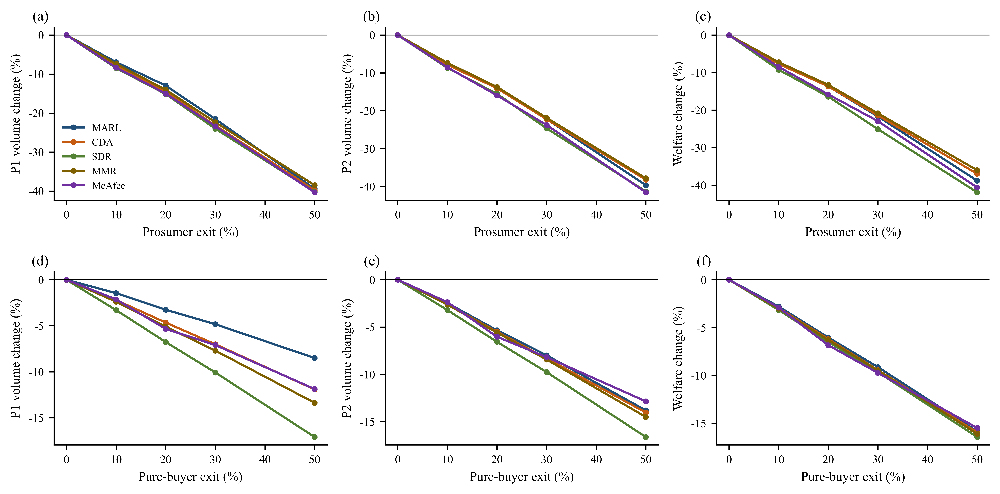

  🖼 network/Fig_layer_criticality.png（绘图数据：network/data/Fig_layer_criticality*.csv）


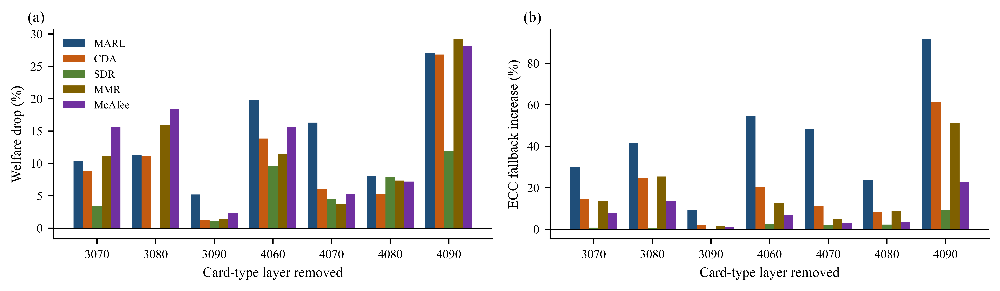

  🖼 network/Fig_size_transfer.png（绘图数据：network/data/Fig_size_transfer*.csv）


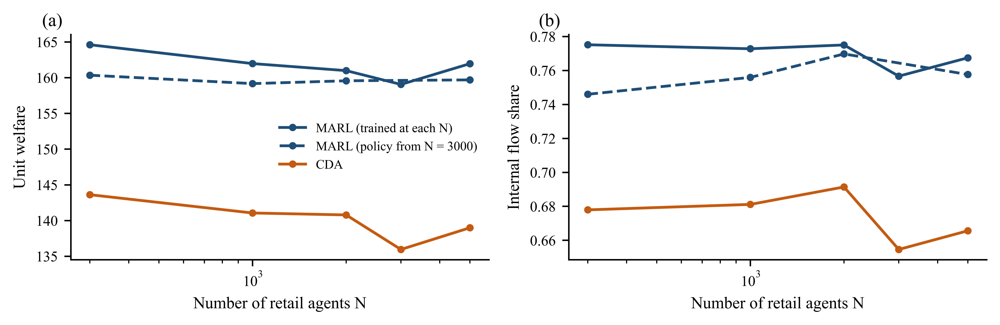

In [5]:
t = run_netshock(workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(t[['scenario', 'method', 'd_welfare_per_day', 'd_p1_vol', 'd_p2_vol', 'd_ecc_fallback_vol', 'd_net_persist_p1', 'd_net_persist_p2']])
Fg.fig_netshock_inter(smoke=SMOKE); Fg.fig_netshock_agents(smoke=SMOKE)
Fg.fig_layer_criticality(smoke=SMOKE); Fg.fig_size_transfer(smoke=SMOKE)

[1/6] inter_remove_largest → skip（0.0 min）| 已用 0.2 min
[2/6] inter_entry_1 → skip（0.0 min）| 已用 0.2 min
[3/6] control → skip（0.0 min）| 已用 0.2 min
[4/6] prosumer_exit_30 → skip（0.0 min）| 已用 0.2 min
[5/6] layer_cut_4090 → skip（0.0 min）| 已用 0.2 min
[6/6] buyer_exit_30 → skip（0.0 min）| 已用 0.2 min
✅ 冲击后恢复完成


,scenario,welfare_at_shock,p1_vol_at_shock,p2_vol_at_shock,welfare_after,p1_vol_after,p2_vol_after,welfare_adapt_gain,welfare_recovered_share,p1_vol_adapt_gain,p1_vol_recovered_share,p2_vol_adapt_gain,p2_vol_recovered_share
0,control,1.000000,1.000000,1.000000,0.973397,0.934872,0.963178,0.000000,NaN,0.000000,NaN,0.000000,NaN
1,inter_remove_largest,0.744085,0.672637,0.717920,0.737347,0.686933,0.712237,0.019865,0.077624,0.079424,0.242618,0.031139,0.110389
2,inter_entry_1,1.057323,1.185914,1.081330,1.056015,1.069914,1.063454,0.025295,NaN,-0.050872,NaN,0.018946,NaN
3,prosumer_exit_30,0.784795,0.785013,0.778797,0.779685,0.758420,0.770032,0.021493,0.099874,0.038535,0.179244,0.028057,0.126837
4,buyer_exit_30,0.905218,0.957048,0.917850,0.892036,0.914149,0.898672,0.013421,0.141600,0.022230,0.517547,0.017644,0.214781
5,layer_cut_4090,0.740918,0.675208,0.721087,0.835528,0.755495,0.782998,0.121214,0.467859,0.145416,0.447719,0.098733,0.353992


  🖼 network/Fig_recovery.png（绘图数据：network/data/Fig_recovery*.csv）





In [3]:
display(run_recovery(workers=WORKERS, smoke=SMOKE, threads=THREADS)); Fg.fig_recovery(smoke=SMOKE)

[1/5] inter_1 / seed 0 → ok（0.0 min）| 已用 7.6 min
[2/5] inter_2 / seed 0 → ok（0.0 min）| 已用 7.6 min
[3/5] inter_0 / seed 0 → ok（0.0 min）| 已用 7.6 min
[4/5] buyer / seed 0 → ok（0.0 min）| 已用 15.0 min
[5/5] prosumer / seed 0 → ok（0.0 min）| 已用 15.0 min
✅ 可利用度检验完成


,seed,deviator,agent,payoff_before,payoff_after,gain,rel_gain,welfare_before,welfare_after,br_days,best_br_day
0,0,inter_0,inter_0,2331.293170,2429.749098,9.845593e+01,4.223232e-02,19179.986201,19458.843418,1000,300
1,0,inter_1,inter_1,2144.404858,2627.275625,4.828708e+02,2.251771e-01,19179.986201,18902.614315,1000,700
2,0,inter_2,inter_2,1305.699672,1480.197196,1.744975e+02,1.336429e-01,19179.986201,18964.326157,1000,200
3,0,prosumer,Prosumer group of 105,5.209131,5.209131,-4.656906e-10,-8.939891e-11,19179.986201,19179.986201,1000,0
4,0,buyer,PureBuyer group of 45,2.542744,2.542744,-1.534506e-11,-6.034841e-12,19179.986201,19179.986201,1000,0


,deviator,payoff_before mean,payoff_before std,payoff_after mean,payoff_after std,gain mean,gain std,rel_gain mean,rel_gain std
0,buyer,2.542744,NaN,2.542744,NaN,-1.534506e-11,NaN,-6.034841e-12,NaN
1,inter_0,2331.293170,NaN,2429.749098,NaN,9.845593e+01,NaN,4.223232e-02,NaN
2,inter_1,2144.404858,NaN,2627.275625,NaN,4.828708e+02,NaN,2.251771e-01,NaN
3,inter_2,1305.699672,NaN,1480.197196,NaN,1.744975e+02,NaN,1.336429e-01,NaN
4,prosumer,5.209131,NaN,5.209131,NaN,-4.656906e-10,NaN,-8.939891e-11,NaN


  🖼 exploit/Fig_exploitability.png（绘图数据：exploit/data/Fig_exploitability*.csv）


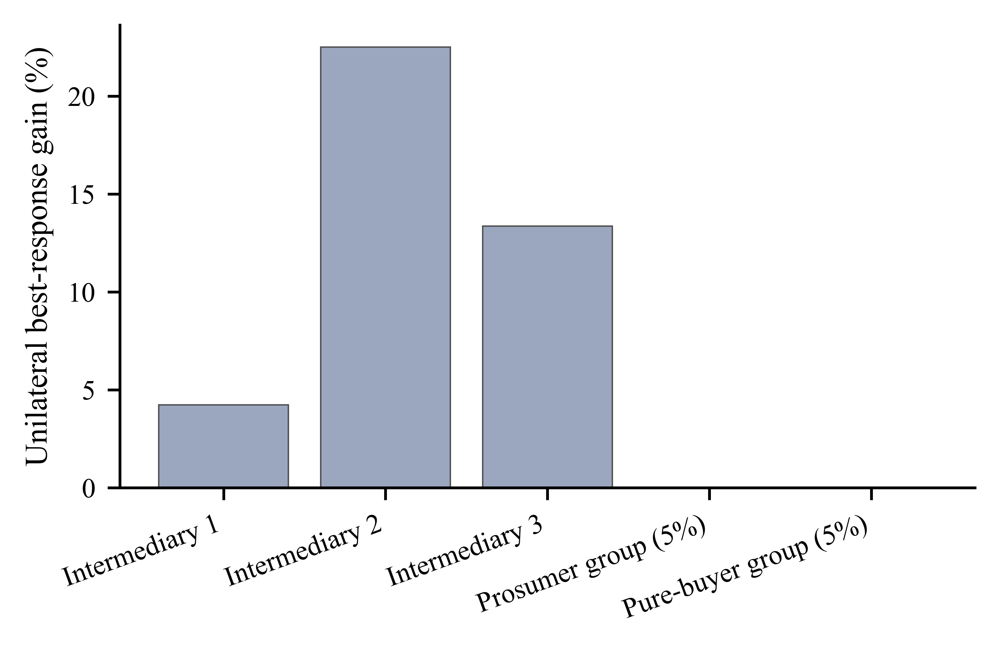

In [7]:
display(run_exploit(workers=WORKERS, smoke=SMOKE, threads=THREADS))
display(A.table_exploit(SMOKE)); Fg.fig_exploit(smoke=SMOKE)

📋 5 个作业：['sens_alpha_0.05', 'sens_alpha_0.15', 'sens_alpha_0.2', 'sens_alpha_0.3', 'sens_alpha_0.4']
[1/5] sens_alpha_0.05 / seed 0 → ok（42.3 min）| 已用 42.3 min
[2/5] sens_alpha_0.2 / seed 0 → ok（42.3 min）| 已用 42.3 min
[3/5] sens_alpha_0.15 / seed 0 → ok（42.5 min）| 已用 42.5 min
[4/5] sens_alpha_0.3 / seed 0 → ok（29.6 min）| 已用 71.9 min
[5/5] sens_alpha_0.4 / seed 0 → ok（29.6 min）| 已用 72.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,alpha,0.05,sens_alpha_0.05,MARL,157.023551,2253.613870,2.316938,4.804537,0.751390,0.345445,8.554110e+05,820509.8497,0.817574,0.681589
1,alpha,0.10,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,8.766107e+05,827775.5041,0.825101,0.698378
2,alpha,0.15,sens_alpha_0.15,MARL,160.643599,2301.478683,2.312816,4.945804,0.768261,0.351090,8.842668e+05,840191.5233,0.831216,0.679062
3,alpha,0.20,sens_alpha_0.2,MARL,163.299827,2512.608783,2.118791,4.879875,0.771426,0.354858,9.083691e+05,846848.3904,0.816746,0.680087
4,alpha,0.30,sens_alpha_0.3,MARL,160.049768,2228.445951,2.727737,4.838213,0.780298,0.351666,9.775509e+05,863210.8950,0.867693,0.708803
5,alpha,0.40,sens_alpha_0.4,MARL,144.062128,2283.503821,2.345529,4.005284,0.792079,0.349585,1.044613e+06,889788.0915,0.843961,0.707215


  🖼 sens_alpha/Fig_sens_alpha.png（绘图数据：sens_alpha/data/Fig_sens_alpha*.csv）





In [8]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_alpha']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('alpha', SMOKE)); Fg.fig_axis('alpha', SMOKE)

📋 4 个作业：['sens_beta_0', 'sens_beta_0.15', 'sens_beta_0.45', 'sens_beta_0.6']
[1/4] sens_beta_0.15 / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/4] sens_beta_0.6 / seed 0 → skip（0.0 min）| 已用 0.0 min
[3/4] sens_beta_0.45 / seed 0 → skip（0.0 min）| 已用 0.0 min
[4/4] sens_beta_0 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,beta,0.00,sens_beta_0,MARL,157.994855,2392.834693,2.310156,4.664333,0.754501,0.342092,874539.2928,827371.5922,0.834246,0.678870
1,beta,0.15,sens_beta_0.15,MARL,162.169109,2315.529029,2.642066,4.872226,0.771006,0.352483,890933.5607,844945.8746,0.824200,0.667721
2,beta,0.30,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
3,beta,0.45,sens_beta_0.45,MARL,161.593089,2107.954747,2.740844,5.093350,0.767912,0.351739,878256.0332,837303.6105,0.814115,0.664902
4,beta,0.60,sens_beta_0.6,MARL,159.933847,2296.698288,1.987641,5.051237,0.759506,0.347441,880394.0697,835470.6250,0.797166,0.686094


  🖼 sens_beta/Fig_sens_beta.png（绘图数据：sens_beta/data/Fig_sens_beta*.csv）





In [4]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_beta']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('beta', SMOKE)); Fg.fig_axis('beta', SMOKE)

📋 2 个作业：['sens_rho_bar_0.02', 'sens_rho_bar_0.05']
[1/2] sens_rho_bar_0.02 / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/2] sens_rho_bar_0.05 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,rho_bar,0.020,sens_rho_bar_0.02,MARL,162.847296,2467.160507,2.330224,4.828201,0.761429,0.343732,887102.5070,835331.5388,0.813973,0.677323
1,rho_bar,0.035,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,rho_bar,0.050,sens_rho_bar_0.05,MARL,155.515612,2171.618629,2.132527,4.914114,0.761141,0.354497,874517.8396,833541.0208,0.811009,0.667266


  🖼 sens_rho_bar/Fig_sens_rho_bar.png（绘图数据：sens_rho_bar/data/Fig_sens_rho_bar*.csv）





In [5]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_rho_bar']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('rho_bar', SMOKE)); Fg.fig_axis('rho_bar', SMOKE)

📋 4 个作业：['sens_vram_corr_0', 'sens_vram_corr_0.1', 'sens_vram_corr_0.3', 'sens_vram_corr_0.5']
[1/4] sens_vram_corr_0.3 / seed 0 → ok（47.0 min）| 已用 47.0 min
[2/4] sens_vram_corr_0.1 / seed 0 → ok（47.5 min）| 已用 47.5 min
[3/4] sens_vram_corr_0 / seed 0 → ok（47.5 min）| 已用 47.6 min
[4/4] sens_vram_corr_0.5 / seed 0 → ok（32.9 min）| 已用 79.9 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,vram_corr,0.00,sens_vram_corr_0,MARL,161.645079,2230.461722,2.898578,4.853725,0.773485,0.342338,910110.9894,872586.4037,0.831053,0.659610
1,vram_corr,0.10,sens_vram_corr_0.1,MARL,160.536858,2521.031452,2.147858,4.696724,0.765825,0.359529,888462.3133,839104.0268,0.838446,0.679728
2,vram_corr,0.18,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
3,vram_corr,0.30,sens_vram_corr_0.3,MARL,158.432764,2291.291128,2.323230,4.828939,0.768652,0.345827,885207.6877,834920.2905,0.825809,0.685529
4,vram_corr,0.50,sens_vram_corr_0.5,MARL,157.187544,2215.203994,2.663179,4.720436,0.755515,0.356690,849886.1072,813381.1817,0.819060,0.703176


  🖼 sens_vram_corr/Fig_sens_vram_corr.png（绘图数据：sens_vram_corr/data/Fig_sens_vram_corr*.csv）





In [6]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_vram_corr']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('vram_corr', SMOKE)); Fg.fig_axis('vram_corr', SMOKE)

📋 6 个作业：['sens_tariff_flat', 'sens_xi_0', 'sens_xi_0.05', 'sens_xi_0.15', 'sens_xi_0.2', 'sens_xi_0.3']
[1/6] sens_xi_0 / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/6] sens_xi_0.05 / seed 0 → skip（0.0 min）| 已用 0.0 min
[3/6] sens_xi_0.15 / seed 0 → skip（0.0 min）| 已用 0.0 min
[4/6] sens_tariff_flat / seed 0 → skip（0.0 min）| 已用 0.0 min
[5/6] sens_xi_0.2 / seed 0 → skip（0.0 min）| 已用 0.0 min
[6/6] sens_xi_0.3 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,xi,0.0,sens_xi_0,MARL,161.592811,2331.634268,2.247267,4.961890,0.770016,0.360241,892257.7635,842157.0361,0.833199,0.685890
1,xi,0.05,sens_xi_0.05,MARL,158.965103,2283.056867,2.401776,4.503918,0.767530,0.345606,840966.9409,811657.0650,0.831880,0.660345
2,xi,0.1,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
3,xi,0.15,sens_xi_0.15,MARL,159.955521,2195.083165,2.311974,4.724366,0.770947,0.348005,851918.9640,810877.8689,0.795408,0.666829
4,xi,0.2,sens_xi_0.2,MARL,161.374736,2152.328266,2.963953,4.872875,0.768948,0.355922,881750.3540,836664.9279,0.813918,0.661674
5,xi,0.3,sens_xi_0.3,MARL,160.468652,2011.480666,2.795700,4.908633,0.777361,0.359379,891411.9194,832237.2326,0.816048,0.642658
6,xi,flat,sens_tariff_flat,MARL,162.782693,2297.196261,2.508374,4.967340,0.772124,0.357564,878648.7280,841619.2781,0.818996,0.664119


  🖼 sens_xi/Fig_sens_xi.png（绘图数据：sens_xi/data/Fig_sens_xi*.csv）





  🖼 main/Fig_hourly_spread.png（绘图数据：main/data/Fig_hourly_spread*.csv）


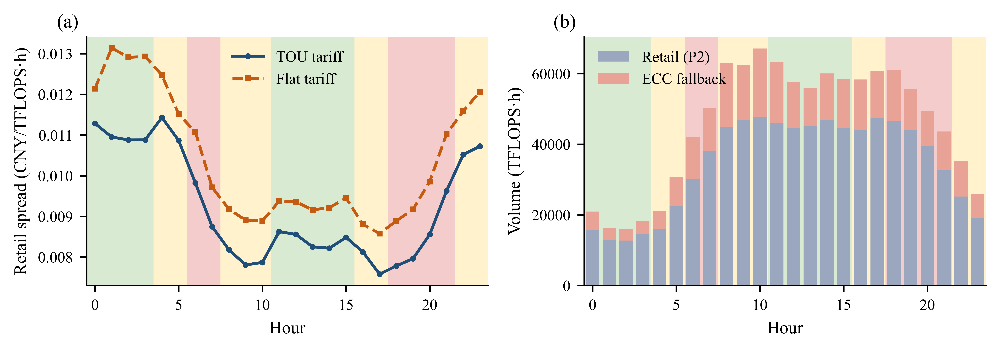

In [5]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_xi'] + ['sens_tariff_flat']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('xi', SMOKE)); Fg.fig_axis('xi', SMOKE)
Fg.fig_hourly('main', SMOKE)                          # 分时 vs 平坦电价的逐时价差

[1/2] sens_eta_1 / seed 0 → ok（70.2 min）| 已用 70.3 min
[2/2] sens_eta_0.8 / seed 0 → ok（72.0 min）| 已用 72.1 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,eta,0.80,sens_eta_0.8,MARL,165.254755,2335.421895,2.630259,5.026059,0.774318,0.366867,892140.2771,844845.5607,0.817669,0.651405
1,eta,0.93,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,eta,1.00,sens_eta_1,MARL,157.574319,2321.316158,2.587667,4.623420,0.756846,0.340403,873769.1421,823848.8162,0.836186,0.688644


  🖼 sens_eta/Fig_sens_eta.png（绘图数据：sens_eta/data/Fig_sens_eta*.csv）





In [8]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_eta']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('eta', SMOKE)); Fg.fig_axis('eta', SMOKE)

📋 2 个作业：['sens_hours_life_26280', 'sens_hours_life_61320']
[1/2] sens_hours_life_61320 / seed 0 → ok（35.0 min）| 已用 35.0 min
[2/2] sens_hours_life_26280 / seed 0 → ok（35.0 min）| 已用 35.1 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,hours_life,26280.0,sens_hours_life_26280,MARL,142.199341,2052.674718,2.326642,4.236165,0.758534,0.359104,872195.3733,838301.6875,0.846370,0.666606
1,hours_life,43800.0,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,hours_life,61320.0,sens_hours_life_61320,MARL,169.060689,2526.434825,2.521490,5.018351,0.771456,0.344543,898793.1017,841989.2733,0.807821,0.685851


  🖼 sens_hours_life/Fig_sens_hours_life.png（绘图数据：sens_hours_life/data/Fig_sens_hours_life*.csv）





In [9]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_hours_life']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('hours_life', SMOKE)); Fg.fig_axis('hours_life', SMOKE)

📋 3 个作业：['sens_delta_0.02', 'sens_delta_0.05', 'sens_delta_0.1']
[1/3] sens_delta_0.02 / seed 0 → ok（43.1 min）| 已用 43.1 min
[2/3] sens_delta_0.1 / seed 0 → ok（43.1 min）| 已用 43.1 min
[3/3] sens_delta_0.05 / seed 0 → ok（43.1 min）| 已用 43.1 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,delta,0.00,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
1,delta,0.02,sens_delta_0.02,MARL,160.184364,2380.681778,2.395019,4.771056,0.760264,0.347497,866578.3894,827323.0476,0.802485,0.635446
2,delta,0.05,sens_delta_0.05,MARL,158.568086,2453.522375,2.573351,4.497756,0.748444,0.340984,855348.4004,820341.4732,0.785345,0.660169
3,delta,0.10,sens_delta_0.1,MARL,160.546916,2012.481633,3.246260,4.953058,0.763274,0.342784,874634.9971,832850.4696,0.822413,0.678307


  🖼 sens_delta/Fig_sens_delta.png（绘图数据：sens_delta/data/Fig_sens_delta*.csv）





In [10]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_delta']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('delta', SMOKE)); Fg.fig_axis('delta', SMOKE)

📋 3 个作业：['sens_forecast_noise_0', 'sens_forecast_noise_0.1', 'sens_forecast_noise_0.4']
[1/3] sens_forecast_noise_0.4 / seed 0 → ok（43.2 min）| 已用 43.2 min
[2/3] sens_forecast_noise_0.1 / seed 0 → ok（43.2 min）| 已用 43.2 min
[3/3] sens_forecast_noise_0 / seed 0 → ok（43.2 min）| 已用 43.3 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,forecast_noise,0.0,sens_forecast_noise_0,MARL,163.602658,2415.049026,2.026053,5.076381,0.786532,0.357596,909831.0471,862547.0606,0.841101,0.646104
1,forecast_noise,0.1,sens_forecast_noise_0.1,MARL,161.585318,2670.908598,2.081297,4.571347,0.771187,0.339942,887708.8393,844701.7826,0.843741,0.662578
2,forecast_noise,0.2,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
3,forecast_noise,0.4,sens_forecast_noise_0.4,MARL,147.229140,2316.410587,1.971922,4.300255,0.690113,0.345856,786243.5130,759037.4855,0.812986,0.661607


  🖼 sens_forecast_noise/Fig_sens_forecast_noise.png（绘图数据：sens_forecast_noise/data/Fig_sens_forecast_noise*.csv）





In [11]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_forecast_noise']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('forecast_noise', SMOKE)); Fg.fig_axis('forecast_noise', SMOKE)

⏳ 生成数据集 N3000_T2800_b7a8050f70：3000 散户，训练+验证 3000 天，测试 100 天
✅ 数据集完成：显存 >8 GB 占 9.8%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.6%
⏳ 生成数据集 N3000_T2800_d0272c4bd7：3000 散户，训练+验证 3000 天，测试 100 天
✅ 数据集完成：显存 >8 GB 占 9.8%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.7%
📋 2 个作业：['sens_no_gpu_ratio_0.2', 'sens_no_gpu_ratio_0.4']
[1/2] sens_no_gpu_ratio_0.2 / seed 0 → ok（35.9 min）| 已用 35.9 min
[2/2] sens_no_gpu_ratio_0.4 / seed 0 → ok（36.2 min）| 已用 36.2 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,no_gpu_ratio,0.2,sens_no_gpu_ratio_0.2,MARL,153.394422,1997.911630,2.619203,4.491322,0.789765,0.370031,887883.8575,819847.5364,0.825558,0.655000
1,no_gpu_ratio,0.3,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,no_gpu_ratio,0.4,sens_no_gpu_ratio_0.4,MARL,164.836371,2232.061067,2.003919,5.379384,0.746945,0.342902,843403.6284,811206.3400,0.831156,0.703355


  🖼 sens_no_gpu_ratio/Fig_sens_no_gpu_ratio.png（绘图数据：sens_no_gpu_ratio/data/Fig_sens_no_gpu_ratio*.csv）





In [12]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_no_gpu_ratio']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('no_gpu_ratio', SMOKE)); Fg.fig_axis('no_gpu_ratio', SMOKE)

📋 3 个作业：['sens_reserve_scale_0', 'sens_reserve_scale_0.5', 'sens_reserve_scale_1.5']
[1/3] sens_reserve_scale_1.5 / seed 0 → ok（37.3 min）| 已用 37.4 min
[2/3] sens_reserve_scale_0.5 / seed 0 → ok（37.6 min）| 已用 37.7 min
[3/3] sens_reserve_scale_0 / seed 0 → ok（37.6 min）| 已用 37.7 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,reserve_scale,0.0,sens_reserve_scale_0,MARL,160.022486,3020.797743,3.333711,3.445012,0.764730,0.348143,907517.5337,830803.9825,0.872234,0.695217
1,reserve_scale,0.5,sens_reserve_scale_0.5,MARL,158.571611,2483.161473,3.143082,4.211446,0.758479,0.350894,893535.2344,829564.5430,0.841991,0.685959
2,reserve_scale,1.0,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
3,reserve_scale,1.5,sens_reserve_scale_1.5,MARL,155.391049,2247.931089,1.708939,4.979481,0.738765,0.341991,855682.9972,814910.0637,0.822929,0.664660


  🖼 sens_reserve_scale/Fig_sens_reserve_scale.png（绘图数据：sens_reserve_scale/data/Fig_sens_reserve_scale*.csv）





In [13]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_reserve_scale']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('reserve_scale', SMOKE)); Fg.fig_axis('reserve_scale', SMOKE)

📋 2 个作业：['sens_ref_speed_0.1', 'sens_ref_speed_0.6']
[1/2] sens_ref_speed_0.1 / seed 0 → ok（29.9 min）| 已用 30.0 min
[2/2] sens_ref_speed_0.6 / seed 0 → ok（30.0 min）| 已用 30.0 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,ref_speed,0.1,sens_ref_speed_0.1,MARL,158.098206,2391.813013,2.611764,4.542467,0.748971,0.342583,859598.0248,815491.4940,0.814885,0.634816
1,ref_speed,0.3,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,ref_speed,0.6,sens_ref_speed_0.6,MARL,160.273915,2331.448514,2.208803,4.926338,0.768098,0.358836,894355.2234,841846.2619,0.800022,0.643584


  🖼 sens_ref_speed/Fig_sens_ref_speed.png（绘图数据：sens_ref_speed/data/Fig_sens_ref_speed*.csv）





In [14]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_ref_speed']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('ref_speed', SMOKE)); Fg.fig_axis('ref_speed', SMOKE)

📋 2 个作业：['sens_la_scale_0', 'sens_la_scale_2']
[1/2] sens_la_scale_2 / seed 0 → ok（30.3 min）| 已用 30.3 min
[2/2] sens_la_scale_0 / seed 0 → ok（30.4 min）| 已用 30.5 min
✅ 完成


,parameter,value,experiment,method,unit_welfare,inter_profit_avg,buyer_savings_pc,prosumer_savings_pc,internal_flow_share,hhi_retail,p1_vol,p2_vol,net_persist_p1,net_persist_p2
0,la_scale,0.0,sens_la_scale_0,MARL,161.539481,2167.152623,2.649361,5.044910,0.768636,0.354854,892334.7963,846197.0679,0.820336,0.654642
1,la_scale,1.0,main,MARL,159.050010,1927.132567,2.797032,5.181552,0.756647,0.349768,876610.7335,827775.5041,0.825101,0.698378
2,la_scale,2.0,sens_la_scale_2,MARL,161.462305,1933.740253,2.301256,5.523112,0.769966,0.354383,878108.8762,843497.3720,0.817181,0.642510


  🖼 sens_la_scale/Fig_sens_la_scale.png（绘图数据：sens_la_scale/data/Fig_sens_la_scale*.csv）





In [15]:
names = [n for n, e in C.EXPERIMENTS.items() if e['group'] == 'sens_la_scale']
run_group(sorted(set(names)), workers=WORKERS, smoke=SMOKE, threads=THREADS)
display(A.table_axis('la_scale', SMOKE)); Fg.fig_axis('la_scale', SMOKE)

⏳ 生成数据集 N300_T3_69cd491123：300 散户，训练+验证 5 天，测试 1 天
✅ 数据集完成：显存 >8 GB 占 10.1%，>24 GB 占 0.0%，产消者任务超出自有卡显存 6.2%
{'N': 300, 'clearing_ms_per_step': 1.0470500008826396, 'policy_ms_per_step': 4.430095833413361, 'update_s_per_day': 0.11536409999825992, 'est_train_s_per_day': 0.24681560002136393}
⏳ 生成数据集 N1000_T3_a4912f2774：1000 散户，训练+验证 5 天，测试 1 天
✅ 数据集完成：显存 >8 GB 占 9.9%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.6%
{'N': 1000, 'clearing_ms_per_step': 1.6333750002862264, 'policy_ms_per_step': 4.813981250057016, 'update_s_per_day': 0.24215320000075735, 'est_train_s_per_day': 0.3968897500089952}
⏳ 生成数据集 N3000_T3_4bdfdaf1c5：3000 散户，训练+验证 5 天，测试 1 天
✅ 数据集完成：显存 >8 GB 占 9.9%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.6%
{'N': 3000, 'clearing_ms_per_step': 3.4547458329446576, 'policy_ms_per_step': 6.814943749911133, 'update_s_per_day': 0.5021648000038113, 'est_train_s_per_day': 0.7486373499923502}
⏳ 生成数据集 N10000_T3_9c19a3c481：10000 散户，训练+验证 5 天，测试 1 天
✅ 数据集完成：显存 >8 GB 占 9.8%，>24 GB 占 0.0%，产消者任务超出自有卡显存 5.6%
{'N': 10000, 'clearin

,N,clearing_ms_per_step,policy_ms_per_step,update_s_per_day,est_train_s_per_day
0,300,1.047050,4.430096,0.115364,0.246816
1,1000,1.633375,4.813981,0.242153,0.396890
2,3000,3.454746,6.814944,0.502165,0.748637
3,10000,10.990575,12.035392,1.475786,2.028409


  🖼 overhead/Fig_overhead.png（绘图数据：overhead/data/Fig_overhead*.csv）


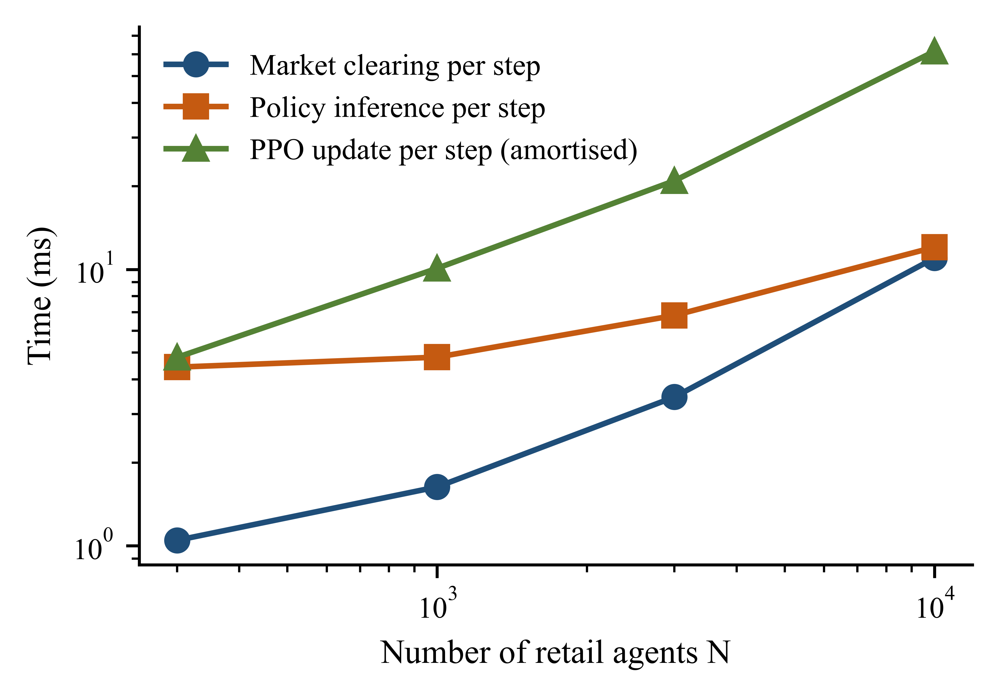

In [16]:
display(run_overhead(SMOKE)); Fg.fig_overhead(smoke=SMOKE)

In [17]:
display(A.describe_runs(SMOKE))

,experiment,seed,done,N,intermediaries,train_days_cfg,test_days,episodes_logged,train_minutes,device,data,reused_from,evaluated
0,tune_t00,0,True,3000,3,2800,100,2800,28.0,cuda,N3000_T2800_43261e831d,,marl
1,tune_t01,0,True,3000,3,2800,100,2800,31.2,cuda,N3000_T2800_43261e831d,,marl
2,tune_t02,0,True,3000,3,2800,100,2800,35.0,cuda,N3000_T2800_43261e831d,,marl
3,tune_t03,0,True,3000,3,2800,100,2800,31.8,cuda,N3000_T2800_43261e831d,,marl
4,tune_t04,0,True,3000,3,2800,100,2800,30.2,cuda,N3000_T2800_43261e831d,,marl
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,struct_n_intermediaries_1,0,True,3000,1,2800,100,2800,29.1,cuda,N3000_T2800_43261e831d,,"cda,marl,mcafee,mmr,sdr"
100,struct_n_intermediaries_2,0,True,3000,2,2800,100,2800,33.9,cuda,N3000_T2800_43261e831d,,"cda,marl,mcafee,mmr,sdr"
101,struct_n_intermediaries_4,0,True,3000,4,2800,100,2800,43.6,cuda,N3000_T2800_43261e831d,,"cda,marl,mcafee,mmr,sdr"
102,struct_n_intermediaries_5,0,True,3000,5,2800,100,2800,39.9,cuda,N3000_T2800_43261e831d,,"cda,marl,mcafee,mmr,sdr"


In [4]:
tabs = A.all_tables(SMOKE)
Fg.all_figures(SMOKE)
for d in sorted(p for p in figures_root(SMOKE).iterdir() if p.is_dir()):
    print(f'{d.name:28s}', sorted(x.name for x in d.glob('*.png')))

✅ 表格已写入 C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\results\tables
绘图代码版本 2026-11-02a（C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\cpm\figures.py）
  🖼 00_data/Fig_tariff_demand.png（绘图数据：00_data/data/Fig_tariff_demand*.csv）
  🖼 00_data/FigS_vram.png（绘图数据：00_data/data/FigS_vram*.csv）
  🖼 main/Fig_training.png（绘图数据：main/data/Fig_training*.csv）
  🖼 main/Fig_surplus_dynamics.png（绘图数据：main/data/Fig_surplus_dynamics*.csv）
  🖼 main/Fig_methods.png（绘图数据：main/data/Fig_methods*.csv）
  🖼 main/Fig_flow_network.png（绘图数据：main/data/Fig_flow_network*.csv）
  🖼 main/Fig_hourly_spread.png（绘图数据：main/data/Fig_hourly_spread*.csv）
  🖼 main/Fig_price_ratio.png（绘图数据：main/data/Fig_price_ratio*.csv）
  🖼 main/Fig_substitution.png（绘图数据：main/data/Fig_substitution*.csv）
  🖼 main/Fig_bidirectional.png（绘图数据：main/data/Fig_bidirectional*.csv）
  🖼 main/Fig_surplus.png（绘图数据：main/data/Fig_surplus*.csv）
  🖼 main/Fig_network_structure.png（绘图数据：main/data/Fig_network_structure*.csv）
  🖼 main/Fig_network_formati